In [1]:
# Build a CNN for Image Classification
# o Build a simple CNN (e.g., 2 conv layers + FC) for MNIST.
# o Compare with MLP performance.
# o Use basic data augmentation

In [2]:
# Import libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import time

I0000 00:00:1794467969.236599    9190 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794467971.387350    9190 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794467980.338670    9190 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# Load and preprocess MNIST using Pandas
train = pd.read_csv("dataset/Handwritten/mnist_train.csv")
test = pd.read_csv("dataset/Handwritten/mnist_test.csv")

x_train = train.iloc[:, 1:].values.astype('float32') / 255.0
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values.astype('float32') / 255.0
y_test = test.iloc[:, 0].values

x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

print("Training data:", x_train.shape)
print("CNN image shape:", x_train_cnn.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
CNN image shape: (60000, 28, 28, 1)
Testing data: (10000, 784)


In [4]:
# Build and train MLP model
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

start = time.time()
h1 = mlp.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)
mlp_time = time.time() - start

mlp_loss, mlp_acc = mlp.evaluate(x_test, y_test, verbose=0)

print("MLP Accuracy:", mlp_acc * 100, "%")
print("MLP Training Time:", round(mlp_time, 2), "seconds")

E0000 00:00:1794468035.946684    9190 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1794468037.887758    9190 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.9118 - loss: 0.3176 - val_accuracy: 0.9600 - val_loss: 0.1508
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9558 - loss: 0.1496 - val_accuracy: 0.9695 - val_loss: 0.1106
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9699 - loss: 0.1036 - val_accuracy: 0.9742 - val_loss: 0.0930
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9766 - loss: 0.0786 - val_accuracy: 0.9773 - val_loss: 0.0822
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9810 - loss: 0.0627 - val_accuracy: 0.9748 - val_loss: 0.0889
MLP Accuracy: 97.39999771118164 %
MLP Training Time: 77.04 seconds


In [5]:
# Build and train CNN with data augmentation
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

start = time.time()
h2 = cnn.fit(x_train_cnn, y_train, epochs=5, batch_size=64, validation_split=0.1)
cnn_time = time.time() - start

cnn_loss, cnn_acc = cnn.evaluate(x_test_cnn, y_test, verbose=0)

print("CNN Accuracy:", cnn_acc * 100, "%")
print("CNN Training Time:", round(cnn_time, 2), "seconds")

W0000 00:00:1794468161.326820    9190 cpu_allocator_impl.cc:82] Allocation of 169344000 exceeds 10% of free system memory.


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.8871 - loss: 0.3581 - val_accuracy: 0.9800 - val_loss: 0.0670
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 43s 51ms/step - accuracy: 0.9602 - loss: 0.1289 - val_accuracy: 0.9842 - val_loss: 0.0522
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 52ms/step - accuracy: 0.9712 - loss: 0.0919 - val_accuracy: 0.9867 - val_loss: 0.0493
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 49ms/step - accuracy: 0.9779 - loss: 0.0744 - val_accuracy: 0.9863 - val_loss: 0.0548
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9803 - loss: 0.0638 - val_accuracy: 0.9870 - val_loss: 0.0442
CNN Accuracy: 98.90000224113464 %
CNN Training Time: 297.74 seconds


MLP Accuracy: 97.4 %
CNN Accuracy: 98.9 %


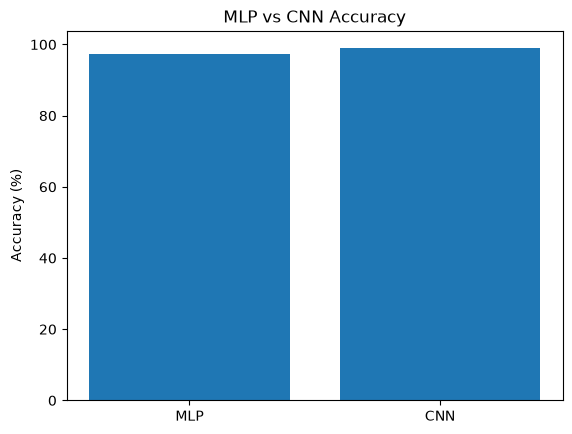

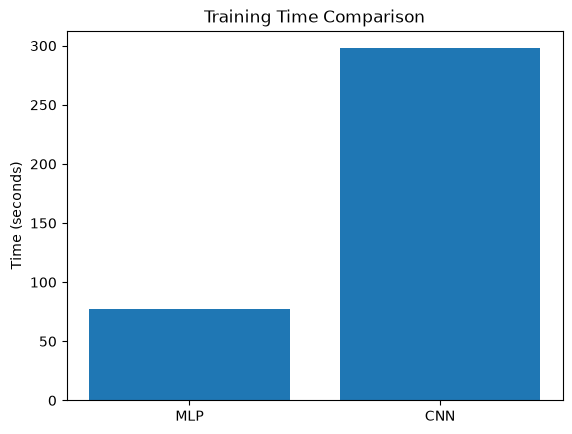

In [6]:
# Compare MLP and CNN accuracy
print("MLP Accuracy:", round(mlp_acc * 100, 2), "%")
print("CNN Accuracy:", round(cnn_acc * 100, 2), "%")

plt.bar(['MLP', 'CNN'], [mlp_acc*100, cnn_acc*100])
plt.title("MLP vs CNN Accuracy")
plt.ylabel("Accuracy (%)")
plt.show()

plt.bar(['MLP', 'CNN'], [mlp_time, cnn_time])
plt.title("Training Time Comparison")
plt.ylabel("Time (seconds)")
plt.show()

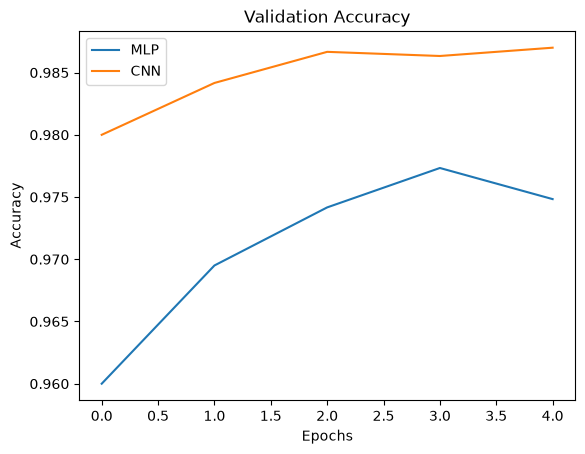

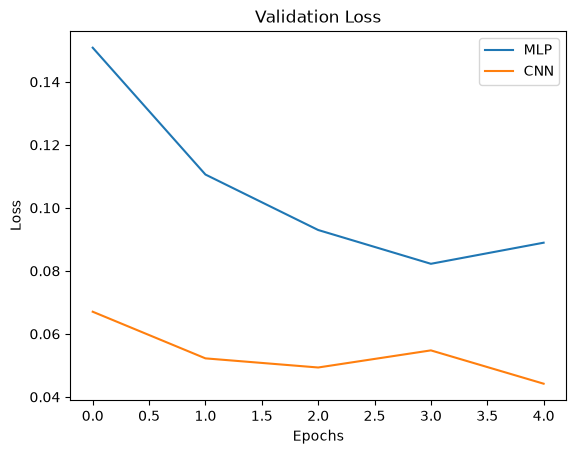

In [7]:
# Plot accuracy and loss curves
plt.plot(h1.history['val_accuracy'], label='MLP')
plt.plot(h2.history['val_accuracy'], label='CNN')
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(h1.history['val_loss'], label='MLP')
plt.plot(h2.history['val_loss'], label='CNN')
plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()